In [ ]:
# Workflow
# Fix 1| 26 April | using ERA5L data as input for kriging instead of insitu data
# Additional step would require converting pixel to points
#  

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
from datetime import datetime
from scipy.optimize import curve_fit
from scipy import stats
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
import warnings
from pyproj import Proj

import geostatspy.geostats as geostats
import geostatspy.GSLIB as GSLIB

plt.style.use('default')
pd.set_option('display.max_columns', None)
warnings.filterwarnings('ignore')

In [2]:
# 1 Data Processing & Coordinate Projection 

def project_coordinates(df):
    """
    Projects Lat/Lon to Metric Coordinates (Kilometers).
    """
    myProj = Proj("+proj=utm +zone=45 +ellps=WGS84 +datum=WGS84 +units=m +no_defs")
    x, y = myProj(df['long'].values, df['lat'].values)
    df['X_km'] = x / 1000.0
    df['Y_km'] = y / 1000.0
    print("Coordinates projected to UTM Zone 45N (km)")
    
    return df

def process_data(file, output_path=None):
    df_insitu_prec = file.copy()
    df_insitu_prec['date'] = pd.to_datetime(df_insitu_prec[['year', 'month', 'day']])

    # Extract Station Metadata
    df_station = df_insitu_prec[['index_no', 'lat', 'long']].drop_duplicates().reset_index(drop=True)
    
    # Define Seasons
    seasons = {
        'winter': [12, 1, 2],
        'pre_monsoon': [3, 4, 5],
        'monsoon': [6, 7, 8, 9],
        'post_monsoon': [10, 11]
    }

    # Map Seasons
    df_seasonal = df_insitu_prec.copy()
    df_seasonal['season'] = df_seasonal['month'].map(
        lambda x: [k for k, v in seasons.items() if x in v][0]
    )
    df_seasonal = df_seasonal[['index_no', 'lat', 'long', 'rainfall_sum', 'date', 'season']]
    df_seasonal['year'] = df_seasonal['date'].dt.year
    df_seasonal['month'] = df_seasonal['date'].dt.month

    # Adjust Year for Winter
    df_seasonal['year_seasonal'] = df_seasonal['year']
    df_seasonal.loc[df_seasonal['month'] == 12, 'year_seasonal'] = df_seasonal.loc[df_seasonal['month'] == 12, 'year'] + 1

    # Aggregate Data
    df_seasonal_sum = df_seasonal.groupby(
        by=['index_no', 'season', 'year_seasonal']
    )[['rainfall_sum']].sum().reset_index()
    
    df_seasonal_averaged = df_seasonal_sum.groupby(
        by=['season', 'index_no']
    )[['rainfall_sum']].mean().reset_index()
    df_seasonal_averaged = df_seasonal_averaged.round(2)

    if output_path:
        df_seasonal_averaged.to_csv(output_path, index=False)

    # Merge Coordinates
    df_final = pd.merge(df_seasonal_averaged, df_station, on='index_no', how='left')
    df_final = df_final[['index_no', 'lat', 'long', 'season', 'rainfall_sum']]
    
    return df_final

In [ ]:
# 2 Detrending & Transformation 

def remove_trend(df, target_col='rainfall_sum'):
    """
    Fits a linear trend surface (Lat + Lon) and returns residuals.
    Crucial for satisfying the Stationarity assumption.
    """
    print(f"\n{'='*50}")
    print(f"TREND ANALYSIS")
    print(f"{'='*50}")
    
    # Prepare X (Coordinates) and y (Value)
    X = df[['lat', 'long']].values
    y = df[target_col].values
    
    # Fit Linear Regression
    trend_model = LinearRegression()
    trend_model.fit(X, y)
    
    # Predict and calculate residuals
    trend = trend_model.predict(X)
    residuals = y - trend
    
    r2 = trend_model.score(X, y)
    print(f"Trend Surface Fit (R²): {r2:.4f}")
    print(f"Linear regression equation: y = B1 (lat) + B2 (lon) + intercept ==", 
            f" y = {trend_model.coef_[0]:.4f}*(lat) + {trend_model.coef_[1]:.4f}*(long) + {trend_model.intercept_:.4f}")

    if r2 > 0.1:
        print("✓ Significant spatial trend detected and removed.")
    else:
        print("ℹ Weak spatial trend, but removing for consistency.")
        
    df['trend'] = trend
    df['residuals'] = residuals
    
    return df, trend_model


def check_normality(data, name='Data'):
    """Normality check on clean data"""
    clean_data = data[np.isfinite(data)]
    
    if len(clean_data) < 3:
        return None, None
    
    # Normality tests
    if len(clean_data) < 5000:
        _, shapiro_p = stats.shapiro(clean_data)
    else:
        shapiro_p = None
    
    return shapiro_p, stats.skew(clean_data)

def apply_transformations(data):
    """Apply multiple transformations to residuals to find best fit"""
    
    transformations = {}
    
    # Normal Score Transformation
    try:
        ns_data, _, _ = geostats.nscore(pd.DataFrame({'val': data}), 'val')
        transformations['nscore'] = {
            'data': ns_data,
            'name': 'Normal Score',
            'inverse': None # NScore inversion requires the lookup table, handled separately if needed
        }
    except:
        pass

    # 2. Original (Raw Residuals)
    transformations['original'] = {
        'data': data,
        'name': 'Raw Residuals',
        'inverse': lambda x: x
    }
    
    # Evaluate
    results = []
    for key, trans in transformations.items():
        clean = trans['data'][np.isfinite(trans['data'])]
        try:
            _, shapiro_p = stats.shapiro(clean) if len(clean) < 5000 else (None, 0.5)
            skewness = stats.skew(clean)
            results.append({
                'method': key,
                'name': trans['name'],
                'shapiro_p': shapiro_p if shapiro_p else 0.5,
                'skewness': abs(skewness),
                'data': trans['data']
            })
        except:
            continue
    
    return pd.DataFrame(results).sort_values('shapiro_p', ascending=False)

In [4]:
# Variogram Models ---

def gaussian_model(h, nugget, psill, range_val):
    """
    Gaussian model. 
    Corrected: uses 3 * (h/a)^2 so 'range_val' is the Effective Range (95% sill)
    """
    return nugget + psill * (1 - np.exp(-3 * (h / range_val)**2))

def spherical_model(h, nugget, psill, range_val):
    """Spherical variogram model"""
    val = np.zeros_like(h, dtype=float)
    idx = h <= range_val
    val[idx] = nugget + psill * (1.5 * (h[idx]/range_val) - 0.5 * (h[idx]/range_val)**3)
    val[~idx] = nugget + psill
    return val

def exponential_model(h, nugget, psill, range_val):
    """
    Exponential model.
    Corrected: uses 3 * (h/a) so 'range_val' is the Effective Range (95% sill)
    """
    return nugget + psill * (1 - np.exp(-3 * h / range_val))

def prepare_wls_weights_cressie(lag, gamma, n_pairs):
    """Weights using Cressie (1985) method: N(h) / h²"""
    valid = np.isfinite(gamma) & np.isfinite(lag) & np.isfinite(n_pairs)
    lag_c = lag[valid]
    gamma_c = gamma[valid]
    n_pairs_c = n_pairs[valid]
    
    mask = lag_c > 0
    lag_c, gamma_c, n_pairs_c = lag_c[mask], gamma_c[mask], n_pairs_c[mask]
    
    if len(lag_c) == 0:
        return np.array([]), np.array([]), np.array([])
    
    # Weights: More weight to bins with many pairs and small lags
    weights = n_pairs_c / (lag_c**2)
    weights[~np.isfinite(weights)] = 1.0
    
    # Normalize and invert for sigma
    weights = weights / np.sum(weights) * len(weights)
    sigma = 1.0 / np.sqrt(weights)
    
    return lag_c, gamma_c, sigma

def fit_variogram_model(model_func, lag_c, gamma_c, sigma, sample_var=None):
    """Fit variogram model with bounds"""
    if len(lag_c) < 3: return None
    
    max_lag = np.max(lag_c)
    max_gamma = np.max(gamma_c)
    
    # Initial Guesses
    p0 = [
        max_gamma * 0.1,  # Nugget
        max_gamma * 0.8,  # Sill
        max_lag * 0.5     # Range
    ]
    
    # Bounds
    bounds = (
        [0, 0, 0.01], 
        [max_gamma*1.5, max_gamma*2.0, max_lag*2.0]
    )
    
    try:
        popt, pcov = curve_fit(
            model_func, lag_c, gamma_c, p0=p0,
            bounds=bounds, sigma=sigma, 
            absolute_sigma=True, maxfev=10000
        )
        
        fitted = model_func(lag_c, *popt)
        residuals = gamma_c - fitted
        rmse = np.sqrt(np.mean(residuals**2))
        
        # R² Calculation
        ss_res = np.sum(residuals**2)
        ss_tot = np.sum((gamma_c - np.mean(gamma_c))**2)
        r_squared = (1 - (ss_res / ss_tot)) if ss_tot > 0 else 0
        
        return {'params': popt, 'rmse': rmse, 'r_squared': r_squared}
    except:
        return None

In [5]:
# --- Section 4: Automatic Lag Optimization (Metric) ---

def calculate_optimal_lag_params(df_subset):
    """
    Calculate lag parameters based on KILOMETER distances.
    """
    coords = df_subset[['X_km', 'Y_km']].values
    
    from scipy.spatial.distance import pdist, squareform
    distances = pdist(coords, metric='euclidean')
    
    min_dist = np.min(distances)
    max_dist = np.max(distances)
    
    # Rule of thumb: Max lag distance should be 1/2 of domain size
    max_lag_dist = max_dist / 2.0
    
    # Lag Bin Size: Usually close to min spacing, or min spacing * 1.5
    lag_dist = max(min_dist, 5.0) # Minimum 5km bin size
    
    # Lag Tolerance: Half of bin size
    lag_tol = lag_dist / 2.0
    
    # Number of lags to reach max_lag_dist
    n_lag = int(max_lag_dist / lag_dist)
    n_lag = max(10, min(n_lag, 20)) # Clamp between 10 and 20 bins

    #Manual lag parameter assignment
    lag_dist, lag_tol, n_lag = 7, 4, 15
    
    print(f"\nLag Optimization (Metric):")
    print(f"  Min Spacing: {min_dist:.2f} km")
    print(f"  Max Extent: {max_dist:.2f} km")
    print(f"  -> Selected Lag Size: {lag_dist:.2f} km")
    print(f"  -> Number of Lags: {n_lag}")
    
    return lag_dist, lag_tol, n_lag


In [6]:
# --- Section 5: IDW-based Cross Validation (Approximate) ---

def cross_validate_approx(df_subset, model_func, params):
    """
    Performs LOOCV using Inverse Variogram Weighting.
    NOTE: This is an approximation of Kriging CV for speed/simplicity.
    """
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    rmse_scores = []
    
    for train_idx, test_idx in kf.split(df_subset):
        train_data = df_subset.iloc[train_idx]
        test_data = df_subset.iloc[test_idx]
        
        for _, test_point in test_data.iterrows():
            # Distances in KM
            dists = np.sqrt(
                (train_data['X_km'] - test_point['X_km'])**2 + 
                (train_data['Y_km'] - test_point['Y_km'])**2
            )
            
            # Variogram Weighting (Proxy for Kriging Weights)
            gamma_vals = model_func(dists, *params)
            gamma_vals = np.maximum(gamma_vals, 1e-6) # Avoid div/0
            weights = 1.0 / gamma_vals
            weights /= np.sum(weights)
            
            pred = np.sum(weights * train_data['transformed'].values)
            actual = test_point['transformed']
            rmse_scores.append((pred - actual)**2)
            
    return np.sqrt(np.mean(rmse_scores)) if rmse_scores else 999

In [7]:
# --- Section 6: Main Analysis Pipeline ---

def perform_comprehensive_analysis(df_input, season_name):
    print(f"\n{'='*70}")
    print(f"ANALYSIS FOR: {season_name.upper()}")
    print(f"{'='*70}")
    
    # 1. Filter Data
    df_subset = df_input[df_input['season'] == season_name].copy()
    
    # 2. Project Coordinates to KM (CRITICAL FIX)
    df_subset = project_coordinates(df_subset)
    
    # 3. Remove Trend (CRITICAL FIX)
    # We analyze the residuals, not the raw rainfall
    df_subset, trend_model = remove_trend(df_subset, 'rainfall_sum')
    
    # 4. Transform Residuals
    print(f"\nSTEP: Data Transformation (on Residuals)")
    trans_results = apply_transformations(df_subset['residuals'].values)
    best_trans = trans_results.iloc[0]
    df_subset['transformed'] = best_trans['data']
    print(f"✓ Best transformation: {best_trans['name']}")
    
    # 5. Visualizations
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Histogram of Raw Rainfall
    axes[0].hist(df_subset['rainfall_sum'], bins=20, color='gray', alpha=0.5)
    axes[0].set_title(f"Raw Rainfall (Mean: {df_subset['rainfall_sum'].mean():.1f})")
    
    # Histogram of Residuals
    axes[1].hist(df_subset['residuals'], bins=20, color='skyblue', edgecolor='k')
    axes[1].set_title("Residuals (Detrended)")
    
    # Histogram of Transformed Residuals (NScore)
    axes[2].hist(df_subset['transformed'], bins=20, color='salmon', edgecolor='k')
    axes[2].set_title(f"Transformed: {best_trans['name']}")
    plt.show()

    # 6. Calc Lags (in KM)
    lag_dist, lag_tol, nlag = calculate_optimal_lag_params(df_subset)
    
    # 7. Experimental Variogram (Using KM and Transformed Residuals)
    # Note: gamv requires coordinates, value. We use X_km, Y_km.
    tmin, tmax = -9999, 9999
    bandh = 9999.9
    isill = 1 # We normalize experimental variogram to sill=1 for comparison
    
    lag_exp, gamma_exp, n_pairs = geostats.gamv(
        df_subset, 'X_km', 'Y_km', 'transformed',
        tmin, tmax, lag_dist, lag_tol, nlag, 
        0, 90, bandh, isill
    )
    
    # 8. Fit Models
    lag_c, gamma_c, sigma = prepare_wls_weights_cressie(lag_exp, gamma_exp, n_pairs)
    
    if len(lag_c) == 0:
        print("Error: No valid lags.")
        return None

    # Sample variance of the transformed residuals (Should be approx 1.0 for NScore)
    sample_var = np.var(df_subset['transformed'])
    print(f"Sample Variance of Transformed Data: {sample_var:.4f}")
    
    models = {
        'Gaussian': gaussian_model,
        'Spherical': spherical_model,
        'Exponential': exponential_model
    }
    colors = {'Gaussian': 'blue', 'Spherical': 'green', 'Exponential': 'red'}
    
    results_list = []
    
    plt.figure(figsize=(10, 6))
    plt.plot(lag_c, gamma_c, 'ko', label='Experimental')
    plt.axhline(sample_var, color='gray', linestyle='--', label='Sill')
    h_fit = np.linspace(0, max(lag_c), 100)
    
    print(f"\n{'Model':<12} {'Nugget':<8} {'Sill':<8} {'Range(km)':<10} {'R²':<8} {'RMSE':<8}")
    print("-" * 60)
    
    for name, func in models.items():
        res = fit_variogram_model(func, lag_c, gamma_c, sigma, sample_var)
        if res:
            p = res['params']
            print(f"{name:<12} {p[0]:<8.3f} {p[1]:<8.3f} {p[2]:<10.1f} {res['r_squared']:.3f} {res['rmse']:.3f}")
            plt.plot(h_fit, func(h_fit, *p), color=colors[name], lw=2, label=f"{name}")
            
            # CV
            cv_rmse = cross_validate_approx(df_subset, func, p)
            
            results_list.append({
                'model': name,
                'params': p,
                'r_squared': res['r_squared'],
                'rmse': res['rmse'],
                'cv_rmse': cv_rmse
            })
            
    plt.xlabel("Distance (km)")
    plt.ylabel("Semivariance")
    plt.title(f"Variogram: {season_name} (Detrended & Projected)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
    
    if not results_list: return None
    
    # Select Best Model (Highest R^2)
    best = max(results_list, key=lambda x: x['r_squared'])
    print(f"\nRecommended Model: {best['model']} (Range: {best['params'][2]:.1f} km)")
    
    return best


ANALYSIS FOR: WINTER
Coordinates projected to UTM Zone 45N (km)

TREND ANALYSIS
Trend Surface Fit (R²): 0.7000
Linear regression equation: y = B1 (lat) + B2 (lon) + intercept ==  y = 29.9912*(lat) + -0.6626*(long) + -725.6192
✓ Significant spatial trend detected and removed.

STEP: Data Transformation (on Residuals)
✓ Best transformation: Normal Score


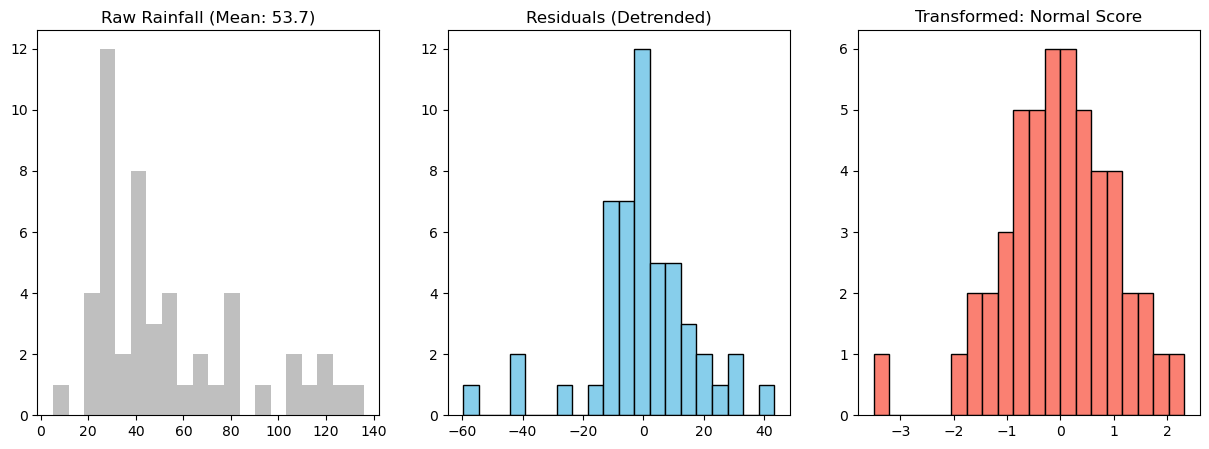


Lag Optimization (Metric):
  Min Spacing: 5.04 km
  Max Extent: 823.15 km
  -> Selected Lag Size: 7.00 km
  -> Number of Lags: 15
Sample Variance of Transformed Data: 1.1114

Model        Nugget   Sill     Range(km)  R²       RMSE    
------------------------------------------------------------
Gaussian     0.343    1.644    196.5      0.399 0.399
Spherical    0.249    1.189    196.5      0.309 0.428
Exponential  0.000    0.698    41.0       0.043 0.503


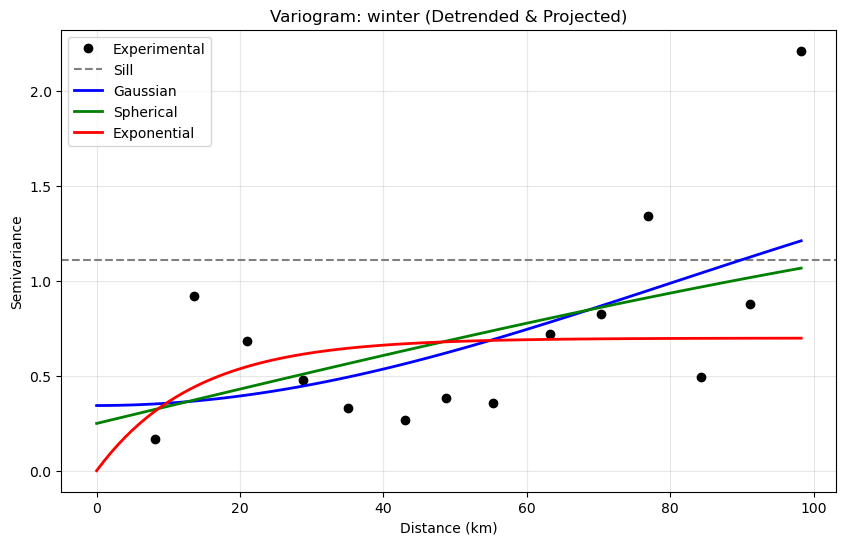


Recommended Model: Gaussian (Range: 196.5 km)


In [8]:
# --- Section 7: Execution ---

# Load Data
insitu_total_df = pd.read_csv(r"..\Data\Processed\Insitu\insitu_rainfall_1991_2020.csv")
train_stations_df = pd.read_csv(r"..\Data\Processed\Split_stations\train_stations.csv")
train_stations = train_stations_df['index_no'].tolist()
insitu_total_df = insitu_total_df[insitu_total_df['index_no'].isin(train_stations)]
insitu_total_df = insitu_total_df[insitu_total_df['year'] >= 2001]


# Process
df_all_seasons = process_data(insitu_total_df)

# Run Analysis for a season
# Note: You can loop this for all seasons
result_winter = perform_comprehensive_analysis(df_all_seasons, 'winter')
#result_monsoon = perform_comprehensive_analysis(df_all_seasons, 'monsoon')
#result_premonsoon = perform_comprehensive_analysis(df_all_seasons, 'pre_monsoon')
#result_postmonsoon = perform_comprehensive_analysis(df_all_seasons, 'post_monsoon')